# Rain in Australia — Exploratory Data Analysis

**Task:** predict whether it rains tomorrow in Australia.

## 1. Setup

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display

from src.data_prep import (NUMERIC_COLUMNS, SEED, GAP_DAYS, clean, split_train_test, time_cv_splits, get_x_y, build_preprocessor,)

DATA_DIR = Path("data")
SOURCE = DATA_DIR / "weatherAUS.csv"
pd.set_option("display.max_columns", None)
np.random.seed(SEED)

print(f"python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")

python 3.13.1 | numpy 2.4.3 | pandas 2.2.3 | scikit-learn 1.8.0


## 2. Load the data and perform an initial audit

In [2]:
raw = pd.read_csv(SOURCE)
numeric_columns_audit = raw.select_dtypes(include="number").columns.tolist()

print(f"Shape: {len(raw):,} rows × {raw.shape[1]} columns")
display(raw.dtypes.rename("dtype").to_frame())
display(raw.head())

Shape: 145,460 rows × 23 columns


,dtype
Date,object
Location,object
MinTemp,float64
MaxTemp,float64
Rainfall,float64
Evaporation,float64
Sunshine,float64
WindGustDir,object
WindGustSpeed,float64
WindDir9am,object


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,WNW,20.0,24.0,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,WSW,4.0,22.0,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,WSW,19.0,26.0,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,E,11.0,9.0,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,NW,7.0,20.0,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


In [3]:
missing_report = pd.DataFrame({
    "missing_n": raw.isna().sum(),
    "missing_pct": (100 * raw.isna().mean()).round(2),
    "unique_non_null": raw.nunique(dropna=True),
}).sort_values("missing_pct", ascending=False)

display(missing_report)
print("Exact duplicates:", int(raw.duplicated().sum()))
print("Duplicate (Date, Location) keys:", int(raw.duplicated(["Date", "Location"]).sum()))
print("Locations:", raw["Location"].nunique())
print("Date range:", raw["Date"].min(), "—", raw["Date"].max())

,missing_n,missing_pct,unique_non_null
Sunshine,69835,48.01,145
Evaporation,62790,43.17,358
Cloud3pm,59358,40.81,10
Cloud9am,55888,38.42,10
Pressure9am,15065,10.36,546
Pressure3pm,15028,10.33,549
WindDir9am,10566,7.26,16
WindGustDir,10326,7.10,16
WindGustSpeed,10263,7.06,67
Humidity3pm,4507,3.10,101


Exact duplicates: 0
Duplicate (Date, Location) keys: 0
Locations: 49
Date range: 2007-11-01 — 2017-06-25


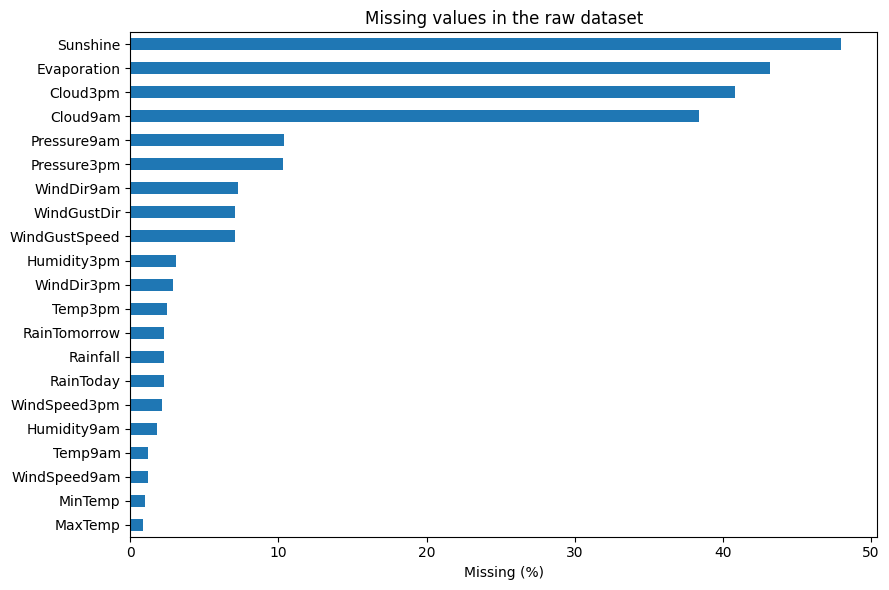

In [4]:
fig, ax = plt.subplots(figsize=(9, 6))
missing_report.loc[missing_report.missing_pct > 0, "missing_pct"].sort_values().plot.barh(ax=ax)
ax.set(title="Missing values in the raw dataset", xlabel="Missing (%)", ylabel="")
fig.tight_layout()
plt.show()

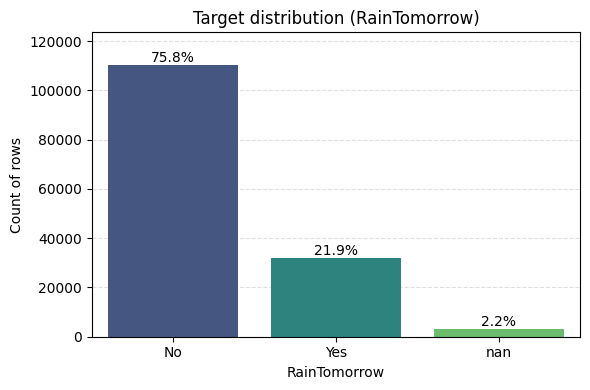

In [5]:

fig, ax = plt.subplots(figsize=(6, 4))

target_counts = raw["RainTomorrow"].value_counts(dropna=False)

x_values = target_counts.index.astype(str)
sns.barplot(x=x_values, y=target_counts.values, ax=ax,
            palette="viridis", hue=x_values, legend=False)

total = target_counts.sum()
for bar in ax.patches:
    height = bar.get_height()
    if height > 0:
        ax.text(bar.get_x() + bar.get_width() / 2,height,f"{height / total:.1%}",ha="center", va="bottom")

ax.set_axisbelow(True)
ax.grid(axis="y", linestyle="--", alpha=0.4)

ax.set(title="Target distribution (RainTomorrow)",xlabel="RainTomorrow", ylabel="Count of rows")
ax.set_ylim(0, target_counts.max() * 1.12)
fig.tight_layout()
plt.show()

## 3. Check invalid and suspicious values

Check ranges and categories once before deciding what needs cleaning. Large but plausible weather measurements are retained.

In [6]:
checks = {
    "MinTemp > MaxTemp": int((raw.MinTemp > raw.MaxTemp).sum()),
    "Cloud9am outside [0, 8]": int((raw.Cloud9am.notna() & ~raw.Cloud9am.between(0, 8)).sum()),
    "Cloud3pm outside [0, 8]": int((raw.Cloud3pm.notna() & ~raw.Cloud3pm.between(0, 8)).sum()),
    "Humidity9am outside [0, 100]": int((raw.Humidity9am.notna() & ~raw.Humidity9am.between(0, 100)).sum()),
    "Humidity3pm outside [0, 100]": int((raw.Humidity3pm.notna() & ~raw.Humidity3pm.between(0, 100)).sum()),
    "Negative Rainfall / Evaporation": int(((raw[["Rainfall", "Evaporation"]] < 0).sum()).sum()),
    "Sunshine outside [0, 24] hours": int((raw.Sunshine.notna() & ~raw.Sunshine.between(0, 24)).sum()),
    "Negative wind speed": int(((raw[["WindGustSpeed", "WindSpeed9am", "WindSpeed3pm"]] < 0).sum()).sum()),
    "Non-positive atmospheric pressure": int(((raw[["Pressure9am", "Pressure3pm"]] <= 0).sum()).sum()),
}

display(pd.Series(checks, name="rows / cells").to_frame())
display(raw[numeric_columns_audit].agg(["min", "median", "max"]).T)

,rows / cells
MinTemp > MaxTemp,0
"Cloud9am outside [0, 8]",2
"Cloud3pm outside [0, 8]",1
"Humidity9am outside [0, 100]",0
"Humidity3pm outside [0, 100]",0
Negative Rainfall / Evaporation,0
"Sunshine outside [0, 24] hours",0
Negative wind speed,0
Non-positive atmospheric pressure,0


,min,median,max
MinTemp,-8.5,12.0,33.9
MaxTemp,-4.8,22.6,48.1
Rainfall,0.0,0.0,371.0
Evaporation,0.0,4.8,145.0
Sunshine,0.0,8.4,14.5
WindGustSpeed,6.0,39.0,135.0
WindSpeed9am,0.0,13.0,130.0
WindSpeed3pm,0.0,19.0,87.0
Humidity9am,0.0,70.0,100.0
Humidity3pm,0.0,52.0,100.0


In [7]:
WIND_DIRECTIONS = {"N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE","S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"}

for col in ["WindGustDir", "WindDir9am", "WindDir3pm", "RainToday", "RainTomorrow"]:
    allowed = {"Yes", "No"} if col.startswith("Rain") else WIND_DIRECTIONS
    print(f"Unexpected categories in {col}:", sorted(set(raw[col].dropna()) - allowed))

valid = raw["Rainfall"].notna() & raw["RainToday"].notna()
expected = np.where(raw.loc[valid, "Rainfall"].gt(1), "Yes", "No")
print("RainToday / Rainfall inconsistencies:", (expected != raw.loc[valid, "RainToday"]).sum())

Unexpected categories in WindGustDir: []
Unexpected categories in WindDir9am: []
Unexpected categories in WindDir3pm: []
Unexpected categories in RainToday: []
Unexpected categories in RainTomorrow: []
RainToday / Rainfall inconsistencies: 0


## 4. Data cleaning

We only do basic cleaning before splitting the data. The cleaning code is in `src/data_prep.py` so all notebooks use the same steps.

- Three cloud values are 9, but the valid range is 0–8, so we replace them with NaN.
- No other invalid values, category issues, or duplicates were found.
- Remove rows with missing RainTomorrow, convert dates, and encode No/Yes as 0/1. Keep missing RainToday values as NaN.
- Leave other missing values as they are. We will handle them later in the pipeline using only training data.

In [8]:
df = clean(raw, verbose=True)
print(f"Removed {len(raw) - len(df):,} rows with missing target; kept {len(df):,} rows")

Cloud9am: 2 values replaced with NaN
Cloud3pm: 1 values replaced with NaN
Removed 3,267 rows with missing target; kept 142,193 rows


## 5. Chronological train/test split with expanding-window train/validation folds

Since the data are ordered by date, we use chronological splits. The model is always trained on the past and evaluated on the future. Random splits could cause data leakage and give overly optimistic results.

- **Test**: the last year (from 2016-07-01). 
- **Training and validation set**: everything before test. We use expanding-window cross-validation with 4 folds. Each fold trains on earlier data and validates on the next year.
- A one-day gap is dropped at every boundary, because `RainTomorrow` refers to the following day.

In [9]:
train_df, gap_df, test_df = split_train_test(df)
folds = time_cv_splits(train_df["Date"])

assert df[["Date", "Location"]].notna().all().all()
assert not df.duplicated(["Date", "Location"]).any()
assert train_df["Date"].max() + pd.Timedelta(days=GAP_DAYS) < test_df["Date"].min()
assert len(train_df) + len(gap_df) + len(test_df) == len(df)

In [10]:
rows = []

for k, (tr, va) in enumerate(folds, start=1):
    tr_part, va_part = train_df.iloc[tr], train_df.iloc[va]
    assert set(tr).isdisjoint(va)
    assert tr_part["Date"].max() + pd.Timedelta(days=GAP_DAYS) < va_part["Date"].min()
    rows.append({
        "split": f"CV fold {k}",
        "train_rows": len(tr_part), "train_end": tr_part["Date"].max().date(),
        "val_rows": len(va_part), "val_start": va_part["Date"].min().date(), "val_end": va_part["Date"].max().date(),
        "val_rain_pct": round(100 * va_part["RainTomorrow"].mean(), 2),
        "new_stations_in_val": len(set(va_part["Location"]) - set(tr_part["Location"])),
    })

rows.append({
    "split": "TEST (final)",
    "train_rows": len(train_df), "train_end": train_df["Date"].max().date(),
    "val_rows": len(test_df), "val_start": test_df["Date"].min().date(), "val_end": test_df["Date"].max().date(),
    "val_rain_pct": round(100 * test_df["RainTomorrow"].mean(), 2),
    "new_stations_in_val": len(set(test_df["Location"]) - set(train_df["Location"])),
})

display(pd.DataFrame(rows))
print(f"Excluded at the train/test boundary: {len(gap_df)} rows")

,split,train_rows,train_end,val_rows,val_start,val_end,val_rain_pct,new_stations_in_val
0,CV fold 1,58590,2012-06-29,14112,2012-07-01,2013-06-30,20.63,3
1,CV fold 2,72698,2013-06-29,17463,2013-07-01,2014-06-30,21.74,0
2,CV fold 3,90161,2014-06-29,17292,2014-07-01,2015-06-30,20.80,0
3,CV fold 4,107454,2015-06-29,17356,2015-07-01,2016-06-29,21.15,0
4,TEST (final),124858,2016-06-29,17286,2016-07-01,2017-06-25,23.17,0


Excluded at the train/test boundary: 49 rows


## 6. Missing Values in Training and Validation Data

We check missing values using only the training and validation data, not the test set. Median imputation is a simple option, but it may not capture differences between locations or seasons.

In [11]:
display((100 * train_df.isna().mean()).sort_values(ascending=False).round(1).to_frame("missing_pct"))

missing_by_location = train_df.groupby("Location")[["Sunshine", "Evaporation", "Cloud3pm"]].agg(lambda column: round(100 * column.isna().mean(), 1))
display(missing_by_location.sort_values("Sunshine", ascending=False).head(10))

,missing_pct
Sunshine,44.1
Evaporation,40.1
Cloud3pm,38.4
Cloud9am,36.7
Pressure9am,9.8
Pressure3pm,9.8
WindDir9am,7.2
WindGustDir,6.7
WindGustSpeed,6.6
WindDir3pm,2.4


,Sunshine,Evaporation,Cloud3pm
Location,,,
Albury,100.0,100.0,53.4
GoldCoast,100.0,100.0,100.0
BadgerysCreek,100.0,100.0,100.0
Bendigo,100.0,55.7,23.2
Ballarat,100.0,100.0,35.5
Katherine,100.0,5.1,29.8
Wollongong,100.0,100.0,54.6
Walpole,100.0,100.0,100.0
Uluru,100.0,100.0,75.7


## 7.  Preprocessing Pipeline

Preprocessing is defined in src/data_prep.py (build_preprocessor) and added to each model's Pipeline. During cross-validation, it is fitted only on the training data and then applied to validation data. This prevents data leakage.

- **Numeric features:** fill missing values with the median calculated on the training fold and add missingness indicators for features with missing values.
- **RainToday:** fill missing values with 0 and add a missingness indicator to distinguish missing values from No.
- **Categorical features:** fill missing values with Missing and apply one-hot encoding. Unseen categories are handled with `handle_unknown="ignore"`.

All preprocessing steps are fitted separately on the training portion of each CV fold to prevent data leakage

In [12]:
x_train, y_train = get_x_y(train_df)

rows = []
for k, (tr, va) in enumerate(folds, start=1):
    prep = build_preprocessor().fit(x_train.iloc[tr])
    Z_val = prep.transform(x_train.iloc[va])
    assert not np.isnan(Z_val).any()
    rows.append({
        "fold": k,
        "n_features": Z_val.shape[1],
        "Sunshine median (fit on this fold's train)": prep.named_transformers_["numeric"].statistics_[NUMERIC_COLUMNS.index("Sunshine")],
        "NaN left in val": int(np.isnan(Z_val).sum()),
    })
display(pd.DataFrame(rows))


,fold,n_features,Sunshine median (fit on this fold's train),NaN left in val
0,1,131,8.3,0
1,2,134,8.3,0
2,3,134,8.4,0
3,4,134,8.4,0
